In [1]:
import pandas as pd
import glob       #trouve les fichiers à partir d1 modèle de nom

In [2]:
fichiers = sorted(glob.glob(r"C:\Users\mvond\Downloads\Apprentissage_Claude\donnees\Rapport_Accident_*.csv"))
len(fichiers)

12

In [3]:
morceaux = []

for fichier in fichiers:
    df_annee = pd.read_csv(fichier, encoding="utf-8-sig", low_memory=False)
    df_annee.columns = df_annee.columns.str.replace("\t", "").str.replace('"', "").str.strip()
    print(df_annee["AN"].iloc[0], df_annee.shape)
    morceaux.append(df_annee)

2011 (182915, 25)
2012 (170284, 25)
2013 (172725, 25)
2014 (153756, 25)
2015 (150932, 25)
2016 (150060, 25)
2017 (152846, 25)
2018 (145108, 25)
2019 (134809, 25)
2020 (95183, 25)
2021 (100603, 25)
2022 (108186, 25)


### 
- morceaux = [] crée une liste vide, comme une boîte où on va ranger chaque année.
- for fichier in fichiers: répète les lignes en dessous pour chaque fichier. 
- On lit le fichier, puis on nettoie les noms de colonnes, comme à l’étape 2.
- print(...) affiche l’année et la taille, pour suivre la progression.
- morceaux.append(df_annee) range le tableau de l’année dans la boîte.
- low_memory=False évite un message d’avertissement de pandas sur les gros fichiers.

In [4]:
# Concatenation des fichiers
accidents = pd.concat(morceaux, ignore_index=True)
accidents.shape

(1717407, 25)

In [5]:
# contrôle par année
accidents["AN"].value_counts().sort_index()

AN
2011    182915
2012    170284
2013    172725
2014    153756
2015    150932
2016    150060
2017    152846
2018    145108
2019    134809
2020     95183
2021    100603
2022    108186
Name: count, dtype: int64

In [6]:
# Création d'une colonne territoire
accidents["TERRITOIRE"]="Reste du Québec"
accidents.loc[accidents["REG_ADM"] == "Capitale-Nationale (03)", "TERRITOIRE"] = "Capitale-Nationale"

###
- La 1ʳᵉ ligne crée une nouvelle colonne et y écrit « Reste du Québec » partout.
- La 2ᵉ ligne utilise .loc[condition, colonne], qui veut dire : « pour les lignes où la région est la Capitale-Nationale, écris “Capitale-Nationale” dans la colonne TERRITOIRE ».

In [7]:
# Marquage des accidents graves
accidents["GRAVE"] = accidents["GRAVITE"] == "Mortel ou grave"

In [8]:
comparaison = accidents.groupby(["AN", "TERRITOIRE"])["GRAVE"].mean().unstack() * 100
comparaison.round(2)

TERRITOIRE,Capitale-Nationale,Reste du Québec
AN,,
2011,0.83,1.18
2012,0.79,1.21
2013,0.94,1.04
2014,0.81,1.07
2015,1.00,1.10
2016,0.99,1.04
2017,0.99,1.06
2018,0.82,1.07
2019,1.07,1.05


<Axes: title={'center': 'Part des accidents mortels ou graves (%)'}, xlabel='AN'>

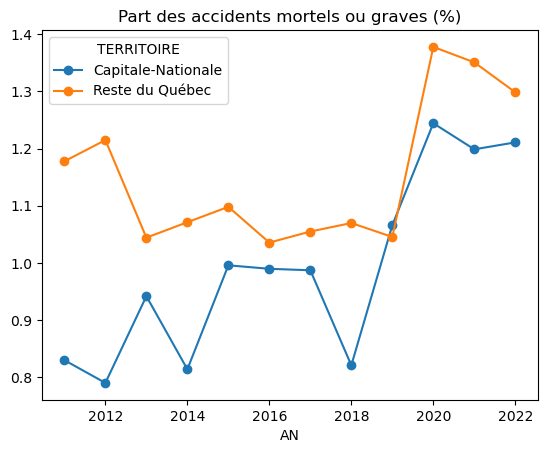

In [9]:
comparaison.plot(title="Part des accidents mortels ou graves (%)", marker="o")

In [10]:
# Nombre d'accident grave par années
accidents.groupby("AN")["GRAVE"].sum()

AN
2011    2089
2012    1994
2013    1785
2014    1603
2015    1642
2016    1548
2017    1604
2018    1521
2019    1412
2020    1300
2021    1346
2022    1397
Name: GRAVE, dtype: int64

In [11]:
accidents["AN"].value_counts().sort_index()

AN
2011    182915
2012    170284
2013    172725
2014    153756
2015    150932
2016    150060
2017    152846
2018    145108
2019    134809
2020     95183
2021    100603
2022    108186
Name: count, dtype: int64

In [12]:
# variation baisse accidents grave
(1300 - 1412) / 1412 * 100

-7.932011331444759

In [13]:
# baisse totale des accidents
(95183 - 134809) / 134809 * 100

-29.394179913803974

## Constats 2011-2022
- La part des accidents mortels ou graves est plus faible dans la Capitale-Nationale que dans le reste du Québec 11 années sur 12 (exception : 2019).
- Le nombre total d'accidents baisse de 2011 à 2019 (-26 %), puis chute en 2020 (COVID).
- En 2020, la part des accidents graves augmente : le total baisse de 29,4 % mais les accidents graves seulement de 7,9 %.
- Hypothèse (non mesurée dans les données) : moins de petits accrochages grâce aux routes moins chargées, et des vitesses plus élevées.

In [14]:
accidents["CD_ETAT_SURFC"].value_counts(dropna=False).sort_index()

CD_ETAT_SURFC
11.0    1004871
12.0     277331
13.0       5714
14.0       8174
15.0      39219
16.0     197287
17.0      41374
18.0      90135
19.0       1558
20.0        261
99.0       5592
NaN       45891
Name: count, dtype: int64

In [15]:
# Dictionnaire de traduction 
etat_surface = {
    11: "Sèche",
    12: "Mouillée",
    13: "Accumulation d'eau",
    14: "Sable, gravier",
    15: "Gadoue, neige fondante",
    16: "Enneigée",
    17: "Neige durcie",
    18: "Glacée",
    19: "Boueuse",
    20: "Huileuse",
    99: "Autre",
}

In [16]:
# Appliquer la traduction
accidents["ETAT_SURFACE"] = accidents["CD_ETAT_SURFC"].map(etat_surface).fillna("Non précisé")

In [17]:
accidents["ETAT_SURFACE"].value_counts()

ETAT_SURFACE
Sèche                     1004871
Mouillée                   277331
Enneigée                   197287
Glacée                      90135
Non précisé                 45891
Neige durcie                41374
Gadoue, neige fondante      39219
Sable, gravier               8174
Accumulation d'eau           5714
Autre                        5592
Boueuse                      1558
Huileuse                      261
Name: count, dtype: int64

In [18]:
accidents["CD_COND_METEO"].value_counts(dropna=False).sort_index()

CD_COND_METEO
11.0    1005652
12.0     340788
13.0       7179
14.0     115958
15.0      12223
16.0       5615
17.0     132977
18.0      35224
19.0       8669
99.0       5612
NaN       47510
Name: count, dtype: int64

In [19]:
# Dictionnaire de traduction
etat_meteo = {
    11: "Clair",
    12: "Couvert (nuageux/sombre)",
    13: "Brouillard/brume",
    14: "Pluie/bruine",
    15: "Averse (pluie forte)",
    16: "Vent fort (pas de poudrerie, pas de pluie)",
    17: "Neige/grêle",
    18: "Poudrerie/tempête de neige",
    19: "Verglas",
    99: "Autre",
}

In [20]:
accidents["METEO"]=accidents["CD_COND_METEO"].map(etat_meteo).fillna("Non précisé")

In [21]:
accidents["METEO"].value_counts()

METEO
Clair                                         1005652
Couvert (nuageux/sombre)                       340788
Neige/grêle                                    132977
Pluie/bruine                                   115958
Non précisé                                     47510
Poudrerie/tempête de neige                      35224
Averse (pluie forte)                            12223
Verglas                                          8669
Brouillard/brume                                 7179
Vent fort (pas de poudrerie, pas de pluie)       5615
Autre                                            5612
Name: count, dtype: int64

In [22]:
cn = accidents[accidents["TERRITOIRE"]=="Capitale-Nationale"]
cn.shape

(163578, 29)

In [23]:
# nombre d’accidents et part des graves selon l’état de la chaussée
surface = cn.groupby("ETAT_SURFACE")["GRAVE"].agg(["count", "mean"])
surface["mean"] = (surface["mean"] * 100).round(2)
surface.sort_values("count", ascending=False)

,count,mean
ETAT_SURFACE,,
Sèche,90167,1.24
Mouillée,30226,0.75
Enneigée,19966,0.37
Non précisé,7036,0.11
Glacée,6932,0.68
"Gadoue, neige fondante",4231,0.85
Neige durcie,2990,0.47
Autre,727,1.10
Accumulation d'eau,617,0.81


In [24]:
# Nombre d'accidents et part des graves selon la météo
meteo_cn = cn.groupby("METEO")["GRAVE"].agg(["count", "mean"])
meteo_cn["mean"] = (meteo_cn["mean"]*100).round(2)
meteo_cn.sort_values("count", ascending=False)

,count,mean
METEO,,
Clair,91622,1.14
Couvert (nuageux/sombre),32488,0.88
Neige/grêle,13833,0.51
Pluie/bruine,11727,0.74
Non précisé,6958,0.20
Poudrerie/tempête de neige,3184,0.79
Averse (pluie forte),1271,1.26
Autre,829,0.36
Verglas,676,1.18


## Constat
- Hiver (Capitale-Nationale, 2011-2022) : 26 898 accidents sur chaussée enneigée ou glacée.
- Paradoxe : ces accidents sont moins souvent graves (0,37 % enneigée, 0,68 % glacée) que sur chaussée sèche (1,24 %).
- Hypothèse : compensation du risque (les conducteurs ralentissent quand la route est visiblement mauvaise).

In [25]:
accidents["CD_ZON_TRAVX_ROUTR"] = accidents["CD_ZON_TRAVX_ROUTR"].fillna("N")
accidents["VITESSE_AUTOR"] = accidents["VITESSE_AUTOR"].str.strip()

In [26]:
mois = {1: "Janvier", 2: "Février", 3: "Mars", 4: "Avril", 5: "Mai", 6: "Juin",
        7: "Juillet", 8: "Août", 9: "Septembre", 10: "Octobre", 11: "Novembre", 12: "Décembre"}
accidents["MOIS"] = accidents["MS_ACCDN"].map(mois)

In [27]:
accidents["CD_ECLRM"].value_counts(dropna=False).sort_index()

CD_ECLRM
0.0          4
1.0    1143507
2.0      85698
3.0     316952
4.0     124315
NaN      46931
Name: count, dtype: int64

In [29]:
# Dictionnaire de traduction
eclairement = {
    1: "Jour et clarté",
    2: "Jour et demi-obscurité",
    3: "Nuit et chemin éclairé",
    4: "Nuit et chemin non éclairé",
}
accidents["ECLAIREMENT"]=accidents["CD_ECLRM"].map(eclairement).fillna("Non précisé")

In [30]:
accidents["ECLAIREMENT"].value_counts()

ECLAIREMENT
Jour et clarté                1143507
Nuit et chemin éclairé         316952
Nuit et chemin non éclairé     124315
Jour et demi-obscurité          85698
Non précisé                     46935
Name: count, dtype: int64

In [31]:
colonnes = ["AN", "MS_ACCDN", "MOIS", "HR_ACCDN", "JR_SEMN_ACCDN",
            "REG_ADM", "TERRITOIRE", "GRAVITE", "GRAVE",
            "NB_VICTIMES_TOTAL", "NB_VEH_IMPLIQUES_ACCDN", "VITESSE_AUTOR",
            "CD_GENRE_ACCDN", "ETAT_SURFACE", "METEO", "ECLAIREMENT",
            "CD_ZON_TRAVX_ROUTR", "IND_AUTO_CAMION_LEGER", "IND_VEH_LOURD",
            "IND_MOTO_CYCLO", "IND_VELO", "IND_PIETON"]
propre = accidents[colonnes]
propre.shape

(1717407, 22)

In [32]:
propre.to_csv(r"C:\Users\mvond\Downloads\Apprentissage_Claude\donnees\accidents_propre.csv",
              index=False, encoding="utf-8-sig")